# A5: Feature Extraction and Text Representation

Convert text into numbers: one-hot encoding, Bag of Words, Document-Term Matrix and TF-IDF. Compare sparse vs dense representations and feature dimensionality / sparsity. Interpret and visualize the feature vectors.

**Dataset:** a custom dataset of 12 short documents, and a subset of 20 Newsgroups (4 groups)

In [2]:
# scikit-learn : CountVectorizer, TfidfVectorizer, SVD
# pandas, matplotlib : tables and plots
!pip install -q scikit-learn pandas matplotlib

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

## Custom dataset: 12 documents on 3 topics

In [4]:
docs = ["India won the cricket match by six wickets",
        "The batsman scored a century in the test match",
        "The bowler took three wickets in the final over",
        "Fans celebrated the cricket world cup victory",
        "Add onion and tomato to the hot pan",
        "Cook the rice with salt and water for ten minutes",
        "This curry recipe needs garlic onion and spices",
        "Bake the cake in a hot oven for thirty minutes",
        "The new phone has a fast processor and a big screen",
        "Python is a popular language for machine learning",
        "The laptop battery lasts ten hours",
        "Machine learning models need data and a fast processor"]
topic = ["cricket"] * 4 + ["cooking"] * 4 + ["technology"] * 4
len(docs)

12

## 1. One-hot encoding

In [5]:
vocab = sorted(set(" ".join(docs).lower().split()))
print(len(vocab), "words in the vocabulary")

sentence = docs[0].lower().split()
one_hot = pd.DataFrame([[1 if v == w else 0 for v in vocab] for w in sentence], index=sentence, columns=vocab)
one_hot.loc[:, (one_hot != 0).any()]          # show only the columns that contain a 1

69 words in the vocabulary


,by,cricket,india,match,six,the,wickets,won
india,0,0,1,0,0,0,0,0
won,0,0,0,0,0,0,0,1
the,0,0,0,0,0,1,0,0
cricket,0,1,0,0,0,0,0,0
match,0,0,0,1,0,0,0,0
by,1,0,0,0,0,0,0,0
six,0,0,0,0,1,0,0,0
wickets,0,0,0,0,0,0,1,0


In [6]:
# document-level one-hot: 1 if the word appears in the document at all
onehot = CountVectorizer(binary=True)
X_onehot = onehot.fit_transform(docs)
pd.DataFrame(X_onehot.toarray(), columns=onehot.get_feature_names_out()).iloc[:4, :12]

,add,and,bake,batsman,battery,big,bowler,by,cake,celebrated,century,cook
0,0,0,0,0,0,0,0,1,0,0,0,0
1,0,0,0,1,0,0,0,0,0,0,1,0
2,0,0,0,0,0,0,1,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,1,0,0


## 2. Bag of Words and the Document-Term Matrix

In [7]:
bow = CountVectorizer()
X_bow = bow.fit_transform(docs)
dtm = pd.DataFrame(X_bow.toarray(), columns=bow.get_feature_names_out(), index=[f"doc{i}" for i in range(len(docs))])
print(dtm.shape, "= documents x words")
dtm

(12, 68) = documents x words


,add,and,bake,batsman,battery,big,bowler,by,cake,celebrated,...,three,to,tomato,took,victory,water,wickets,with,won,world
doc0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0
doc1,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
doc2,0,0,0,0,0,0,1,0,0,0,...,1,0,0,1,0,0,1,0,0,0
doc3,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,1
doc4,1,1,0,0,0,0,0,0,0,0,...,0,1,1,0,0,0,0,0,0,0
doc5,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0
doc6,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
doc7,0,0,1,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
doc8,0,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
doc9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
bow_nostop = CountVectorizer(stop_words="english")       # drop "the", "and", "a" ...
X_bow2 = bow_nostop.fit_transform(docs)
print("words without stop words:", X_bow2.shape[1])

words without stop words: 54


## 3. TF-IDF

In [9]:
tfidf = TfidfVectorizer(stop_words="english")
X_tfidf = tfidf.fit_transform(docs)
tfidf_df = pd.DataFrame(X_tfidf.toarray(), columns=tfidf.get_feature_names_out()).round(2)
tfidf_df.iloc[:4, :15]

,add,bake,batsman,battery,big,bowler,cake,celebrated,century,cook,cricket,cup,curry,data,fans
0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.42,0.00,0.0,0.0,0.00
1,0.0,0.0,0.46,0.0,0.0,0.00,0.0,0.00,0.46,0.0,0.00,0.00,0.0,0.0,0.00
2,0.0,0.0,0.00,0.0,0.0,0.52,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.0,0.00
3,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.42,0.00,0.0,0.36,0.42,0.0,0.0,0.42


In [10]:
# idf of a few words: rare words get a higher weight
idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
pd.concat([idf.head(4), idf.tail(4)]).round(2)

fast       2.47
cricket    2.47
match      2.47
minutes    2.47
victory    2.87
water      2.87
won        2.87
world      2.87
dtype: float64

In [11]:
# top words of each document
for i in [0, 4, 9]:
    row = tfidf_df.iloc[i]
    print(docs[i], "->", list(row.sort_values(ascending=False).index[:3]))

India won the cricket match by six wickets -> ['india', 'won', 'match']
Add onion and tomato to the hot pan -> ['add', 'pan', 'tomato']
Python is a popular language for machine learning -> ['language', 'popular', 'python']


## 4. Visualize the feature vectors

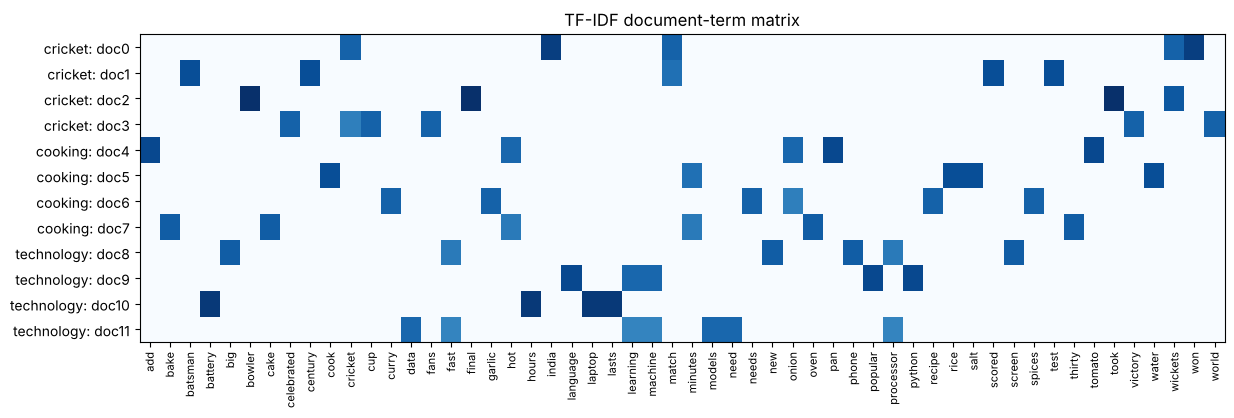

In [12]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.imshow(tfidf_df.values, cmap="Blues", aspect="auto")
ax.set_yticks(range(len(docs)), [f"{t}: doc{i}" for i, t in enumerate(topic)])
ax.set_xticks(range(tfidf_df.shape[1]), tfidf_df.columns, rotation=90, fontsize=8)
ax.set_title("TF-IDF document-term matrix"); plt.show()

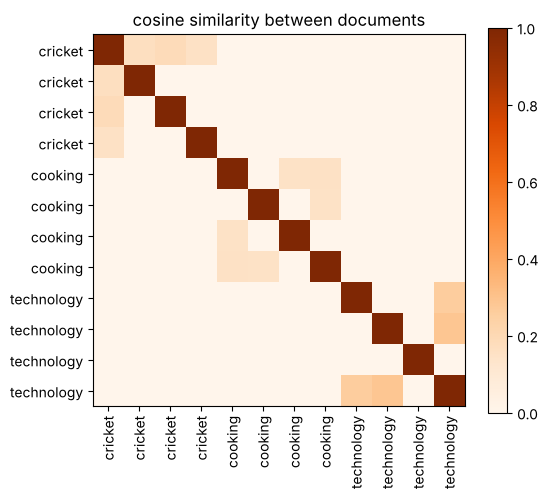

In [13]:
sim = cosine_similarity(X_tfidf)
plt.figure(figsize=(6, 5)); plt.imshow(sim, cmap="Oranges")
plt.xticks(range(12), topic, rotation=90); plt.yticks(range(12), topic)
plt.colorbar(); plt.title("cosine similarity between documents"); plt.show()

## 5. 20 Newsgroups subset

In [14]:
news = pd.read_json("https://raw.githubusercontent.com/selva86/datasets/master/newsgroups.json")
groups = ["rec.sport.hockey", "sci.space", "comp.graphics", "talk.politics.guns"]
news = news[news["target_names"].isin(groups)].reset_index(drop=True)
news["content"] = news["content"].str.split("\n\n", n=1).str[1].fillna("")   # drop the email header (From:, Subject:, ...)
print(news.shape)
news["target_names"].value_counts()

(2323, 3)


target_names
rec.sport.hockey      600
sci.space             593
comp.graphics         584
talk.politics.guns    546
Name: count, dtype: int64

In [15]:
tfidf20 = TfidfVectorizer(stop_words="english")
X20 = tfidf20.fit_transform(news["content"])
print("shape:", X20.shape)

shape: (2323, 37779)


## 6. Sparse vs dense, dimensionality and sparsity

In [16]:
n_cells = X20.shape[0] * X20.shape[1]
sparse_mb = (X20.data.nbytes + X20.indices.nbytes + X20.indptr.nbytes) / 1e6
dense_mb = n_cells * 8 / 1e6                         # 8 bytes per float64 number
print(f"non-zero values: {X20.nnz:,} of {n_cells:,} -> density {X20.nnz / n_cells:.3%}")
print(f"memory: sparse {sparse_mb:.1f} MB vs dense {dense_mb:,.0f} MB")

non-zero values: 241,991 of 87,760,617 -> density 0.276%
memory: sparse 2.9 MB vs dense 702 MB


In [17]:
rows = []
for min_df in [1, 2, 5, 10, 50]:
    v = TfidfVectorizer(stop_words="english", min_df=min_df)      # ignore words in fewer than min_df documents
    X = v.fit_transform(news["content"])
    rows.append({"min_df": min_df, "features": X.shape[1], "density": f"{X.nnz / (X.shape[0] * X.shape[1]):.3%}"})
pd.DataFrame(rows)

,min_df,features,density
0,1,37779,0.276%
1,2,18798,0.511%
2,5,8384,1.005%
3,10,4757,1.556%
4,50,860,4.641%


In [18]:
# dense representation: reduce to 100 dimensions with SVD (every value non-zero)
svd = TruncatedSVD(n_components=100, random_state=0)
X_dense = svd.fit_transform(X20)
print("dense shape:", X_dense.shape, "| memory:", round(X_dense.nbytes / 1e6, 1), "MB")

dense shape: (2323, 100) | memory: 1.9 MB


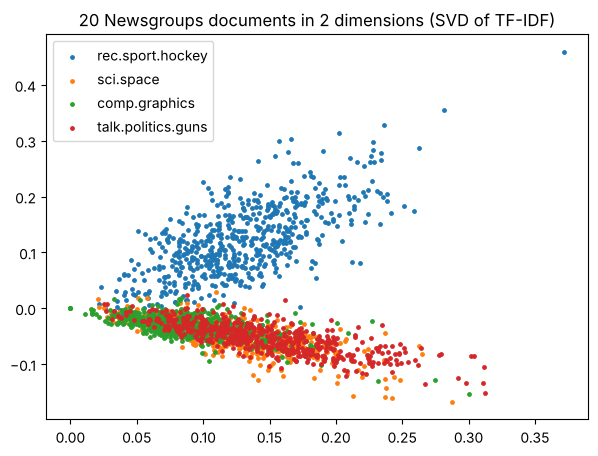

In [19]:
points = TruncatedSVD(n_components=2, random_state=0).fit_transform(X20)
plt.figure(figsize=(7, 5))
for g in groups:
    m = news["target_names"] == g
    plt.scatter(points[m, 0], points[m, 1], s=6, label=g)
plt.legend(); plt.title("20 Newsgroups documents in 2 dimensions (SVD of TF-IDF)"); plt.show()

In [20]:
# words that best describe each group: highest average TF-IDF
words20 = tfidf20.get_feature_names_out()
for g in groups:
    mean = np.asarray(X20[(news["target_names"] == g).values].mean(axis=0)).ravel()
    print(f"{g:<20}", list(words20[mean.argsort()[::-1][:8]]))

rec.sport.hockey     ['game', 'team', 'hockey', 'ca', 'play', 'edu', 'players', 'season']
sci.space            ['space', 'nasa', 'edu', 'henry', 'writes', 'moon', 'article', 'like']
comp.graphics        ['graphics', 'thanks', 'edu', 'image', 'files', 'file', 'program', 'know']
talk.politics.guns   ['gun', 'people', 'edu', 'com', 'guns', 'don', 'writes', 'article']


## Conclusion
- One-hot and BoW only record presence or counts; TF-IDF also down-weights words that occur in many documents.
- The document-term matrix is very sparse: almost every entry is 0, so sparse storage needs a tiny fraction of the memory of a dense array.
- min_df removes rare words and shrinks the number of features a lot.
- SVD gives a short dense vector per document; in 2 dimensions the newsgroups already separate partly, and the top TF-IDF words describe each group.